In [1]:
!pip install -q segmentation-models-pytorch

import torch
print('torch', torch.__version__, '| CUDA:', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NO GPU')

torch 2.11.0+cu130 | CUDA: True | Tesla T4


In [ ]:
import os, glob, json, time, random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# CamVid frames are 720x960 (H x W). 384x512 keeps the same 3:4 aspect ratio
# and is divisible by 32, which DeepLabV3+ needs (encoder downsamples by 32).
IN_H, IN_W = 384, 512

BATCH   = 8
EPOCHS  = 80          # set to 2 for a quick test run first
LR_ENC  = 1e-4        # pretrained encoder: small LR so ImageNet features are not destroyed
LR_DEC  = 1e-3        # new decoder + head: larger LR, they start from random weights
WD      = 1e-4
IGNORE  = 255         # label value for Void / unlabeled pixels
OUT_DIR = '/kaggle/working'

# The 11 target classes, index in this list = label value in the masks
CLASS_NAMES = ['Sky', 'Building', 'Pole', 'Road', 'Pavement', 'Tree',
               'SignSymbol', 'Fence', 'Car', 'Pedestrian', 'Bicyclist']
K = len(CLASS_NAMES)

# Display color per class (taken from the original CamVid color of that class)
CMAP = [[128, 128, 128], [128, 0, 0], [192, 192, 128], [128, 64, 128], [0, 0, 192],
        [128, 128, 0], [192, 128, 128], [64, 64, 128], [64, 0, 128], [64, 64, 0],
        [0, 128, 192]]

# ImageNet normalization, because the encoder was pretrained on ImageNet
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD  = np.array([0.229, 0.224, 0.225], np.float32)

In [3]:
hits = glob.glob('/kaggle/input/**/class_dict.csv', recursive=True)
assert hits, 'class_dict.csv not found: did you Add Input the CamVid dataset?'
ROOT = os.path.dirname(hits[0])
print('ROOT =', ROOT)
for s in ['train', 'val', 'test']:
    print(f'{s:5s}: {len(glob.glob(f"{ROOT}/{s}/*.png"))} images, '
          f'{len(glob.glob(f"{ROOT}/{s}_labels/*.png"))} labels')

ROOT = /kaggle/input/datasets/carlolepelaars/camvid/CamVid
train: 369 images, 369 labels
val  : 100 images, 100 labels
test : 232 images, 232 labels


In [ ]:
# Which original CamVid classes go into each of the 11 target classes
# 'Void' is not listed, so it stays IGNORE (255)
GROUPS = {
    'Sky':        ['Sky'],
    'Building':   ['Building', 'Wall', 'Bridge', 'Tunnel', 'Archway'],
    'Pole':       ['Column_Pole', 'TrafficCone'],
    'Road':       ['Road', 'LaneMkgsDriv', 'LaneMkgsNonDriv'],
    'Pavement':   ['Sidewalk', 'ParkingBlock', 'RoadShoulder'],
    'Tree':       ['Tree', 'VegetationMisc'],
    'SignSymbol': ['SignSymbol', 'Misc_Text', 'TrafficLight'],
    'Fence':      ['Fence'],
    'Car':        ['Car', 'SUVPickupTruck', 'Truck_Bus', 'Train', 'OtherMoving'],
    'Pedestrian': ['Pedestrian', 'Child', 'CartLuggagePram', 'Animal'],
    'Bicyclist':  ['Bicyclist', 'MotorcycleScooter'],
}

cd = pd.read_csv(f'{ROOT}/class_dict.csv', skipinitialspace=True)
cd.columns = [c.strip() for c in cd.columns]
name2rgb = {str(r['name']).strip(): (int(r['r']), int(r['g']), int(r['b']))
            for _, r in cd.iterrows()}

# Lookup table indexed by the packed color R*65536 + G*256 + B.
# Every color defaults to IGNORE, only the 31 known colors get a class index.
LUT = np.full(256 ** 3, IGNORE, np.uint8)
used = set()
for idx, cname in enumerate(CLASS_NAMES):
    for orig in GROUPS[cname]:
        r, g, b = name2rgb[orig]
        LUT[(r << 16) | (g << 8) | b] = idx
        used.add(orig)
print(f'{len(name2rgb)} CamVid classes, {len(used)} mapped, '
      f'unmapped (-> ignore): {sorted(set(name2rgb) - used)}')

def rgb_to_mask(rgb):
    """RGB color-coded label (H,W,3) -> class-index mask (H,W) with values 0..10 or 255."""
    rgb = rgb.astype(np.int32)
    return LUT[(rgb[..., 0] << 16) | (rgb[..., 1] << 8) | rgb[..., 2]]

CMAP_NP = np.array(CMAP + [[0, 0, 0]], np.uint8)   # extra black row for ignore
def colorize(mask):
    """Class-index mask -> RGB image for display."""
    return CMAP_NP[np.where(mask == IGNORE, K, mask)]

32 CamVid classes, 31 mapped, unmapped (-> ignore): ['Void']


train (369, 384, 512, 3), val (100, 384, 512, 3)  (111s)


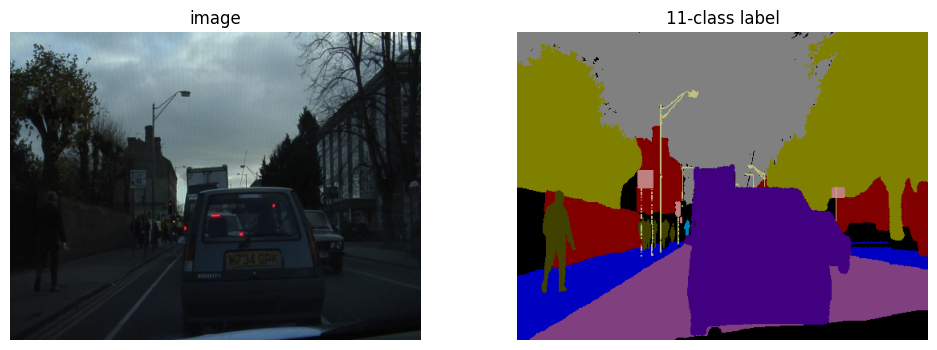

In [ ]:
def read_rgb(path):
    # OpenCV loads BGR, converting to RGB
    return cv2.cvtColor(cv2.imread(path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)

def label_path(split, img_path):
    base = os.path.splitext(os.path.basename(img_path))[0]
    return f'{ROOT}/{split}_labels/{base}_L.png'

def load_split(split):
    files = sorted(glob.glob(f'{ROOT}/{split}/*.png'))
    X = np.zeros((len(files), IN_H, IN_W, 3), np.uint8)
    Y = np.zeros((len(files), IN_H, IN_W), np.uint8)
    for i, f in enumerate(files):
        X[i] = cv2.resize(read_rgb(f), (IN_W, IN_H), interpolation=cv2.INTER_AREA)
        m = rgb_to_mask(read_rgb(label_path(split, f)))
        Y[i] = cv2.resize(m, (IN_W, IN_H), interpolation=cv2.INTER_NEAREST)
    return files, X, Y

t0 = time.time()
train_files, Xtr, Ytr = load_split('train')
val_files,   Xva, Yva = load_split('val')
print(f'train {Xtr.shape}, val {Xva.shape}  ({time.time() - t0:.0f}s)')

# Sanity check: one image + its 11-class mask
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(Xtr[0]); ax[0].set_title('image'); ax[0].axis('off')
ax[1].imshow(colorize(Ytr[0])); ax[1].set_title('11-class label'); ax[1].axis('off')
plt.show()

In [6]:
# freq_c = pixels of class c / total pixels of the images in which c appears
# weight_c = median(freq) / freq_c  -> rare classes (Pole, Pedestrian, Bicyclist) get larger weights
pix     = np.array([(Ytr == c).sum() for c in range(K)], np.float64)
img_has = np.array([(Ytr == c).any(axis=(1, 2)).sum() for c in range(K)], np.float64)
freq    = pix / np.maximum(img_has * IN_H * IN_W, 1)
class_w = np.median(freq) / np.maximum(freq, 1e-12)

share = pix / (Ytr.size)
print(f'{"class":11s} {"share%":>7s} {"weight":>7s}')
for c in range(K):
    print(f'{CLASS_NAMES[c]:11s} {100 * share[c]:7.2f} {class_w[c]:7.3f}')
print(f'{"Void":11s} {100 * (Ytr == IGNORE).mean():7.2f}')

class        share%  weight
Sky           15.20   0.283
Building      24.17   0.179
Pole           1.04   4.147
Road          30.30   0.143
Pavement       7.42   0.565
Tree          10.96   0.361
SignSymbol     1.15   3.592
Fence          1.67   1.488
Car            4.30   1.000
Pedestrian     0.68   5.761
Bicyclist      0.48   4.553
Void           2.62


In [ ]:
def to_tensor(img):
    """uint8 HxWx3 RGB -> normalized float tensor 3xHxW."""
    x = (img.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

class CamVidDS(Dataset):
    def __init__(self, X, Y, train):
        self.X, self.Y, self.train = X, Y, train

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img, m = self.X[i], self.Y[i]
        if self.train:
            # 1) random scale 0.75x..1.25x (same scale for image and mask)
            s = np.random.uniform(0.75, 1.25)
            h, w = int(IN_H * s + 0.5), int(IN_W * s + 0.5)
            img = cv2.resize(img, (w, h), interpolation=cv2.INTER_LINEAR)
            m   = cv2.resize(m,   (w, h), interpolation=cv2.INTER_NEAREST)
            # 2) pad if smaller than the crop (mask padded with IGNORE so it is not learned)
            ph, pw = max(IN_H - h, 0), max(IN_W - w, 0)
            if ph or pw:
                img = cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=(0, 0, 0))
                m   = cv2.copyMakeBorder(m,   0, ph, 0, pw, cv2.BORDER_CONSTANT, value=IGNORE)
            # 3) random crop back to 384x512
            y0 = np.random.randint(0, img.shape[0] - IN_H + 1)
            x0 = np.random.randint(0, img.shape[1] - IN_W + 1)
            img, m = img[y0:y0 + IN_H, x0:x0 + IN_W], m[y0:y0 + IN_H, x0:x0 + IN_W]
            # 4) random horizontal flip (road scenes are left-right symmetric)
            if np.random.rand() < 0.5:
                img, m = img[:, ::-1], m[:, ::-1]
        return to_tensor(img), torch.from_numpy(np.ascontiguousarray(m)).long()

def worker_init(worker_id):
    # different numpy seeds for every DataLoader worker
    np.random.seed((torch.initial_seed() + worker_id) % 2 ** 32)

train_loader = DataLoader(CamVidDS(Xtr, Ytr, True), batch_size=BATCH, shuffle=True,
                          num_workers=2, drop_last=True, pin_memory=True,
                          worker_init_fn=worker_init)
val_loader   = DataLoader(CamVidDS(Xva, Yva, False), batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
print(len(train_loader), 'train batches,', len(val_loader), 'val batches')

46 train batches, 13 val batches


In [ ]:
# DeepLabV3+ with a ResNet-18 encoder pretrained on ImageNet (transfer learning)
model = smp.DeepLabV3Plus(encoder_name='resnet18', encoder_weights='imagenet',
                          classes=K).to(DEVICE)

# Pixel-wise cross-entropy, weighted against class imbalance, Void pixels ignored.
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_w, dtype=torch.float32, device=DEVICE),
    ignore_index=IGNORE)

# Different learning rates: small for the pretrained encoder, larger for the new parts.
opt = torch.optim.AdamW([
    {'params': model.encoder.parameters(), 'lr': LR_ENC},
    {'params': list(model.decoder.parameters()) +
               list(model.segmentation_head.parameters()), 'lr': LR_DEC},
], weight_decay=WD)

# "Poly" schedule (as in the DeepLab papers): LR decays smoothly to 0 over training.
sched = torch.optim.lr_scheduler.PolynomialLR(
    opt, total_iters=EPOCHS * len(train_loader), power=0.9)
scaler = torch.amp.GradScaler('cuda')

def confusion(pred, gt):
    """KxK confusion matrix (rows = ground truth, cols = prediction), Void excluded."""
    v = gt != IGNORE
    return torch.bincount(gt[v] * K + pred[v], minlength=K * K).reshape(K, K)

def scores(cm):
    cm = cm.astype(np.float64)
    tp = np.diag(cm)
    iou   = tp / np.maximum(cm.sum(0) + cm.sum(1) - tp, 1)   # TP / (TP + FP + FN)
    acc_c = tp / np.maximum(cm.sum(1), 1)                    # per-class recall
    return dict(pixel_acc=tp.sum() / cm.sum(), mean_acc=acc_c.mean(),
                miou=iou.mean(), iou=iou, class_acc=acc_c)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

In [9]:
history, best_miou = [], -1.0
for ep in range(1, EPOCHS + 1):
    t0 = time.time()

    # ---- train ----
    model.train(); train_loss = 0.0
    for x, y in train_loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)

    # ---- validate ----
    model.eval(); val_loss = 0.0
    cm = torch.zeros(K, K, dtype=torch.long, device=DEVICE)
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            val_loss += criterion(out, y).item()
            cm += confusion(out.argmax(1), y)
    val_loss /= len(val_loader)
    s = scores(cm.cpu().numpy())

    history.append(dict(epoch=ep, train_loss=train_loss, val_loss=val_loss,
                        val_miou=s['miou'], val_pixel_acc=s['pixel_acc']))
    tag = ''
    if s['miou'] > best_miou:
        best_miou = s['miou']
        torch.save(model.state_dict(), f'{OUT_DIR}/best_model.pth')
        tag = '  <- best, saved'
    print(f'ep {ep:3d} | train {train_loss:.4f} | val {val_loss:.4f} | '
          f'val mIoU {s["miou"]:.4f} | val acc {s["pixel_acc"]:.4f} | '
          f'{time.time() - t0:.0f}s{tag}')

print('best val mIoU:', best_miou)

ep   1 | train 1.1004 | val 0.7098 | val mIoU 0.5098 | val acc 0.8219 | 12s  <- best, saved
ep   2 | train 0.6322 | val 0.6101 | val mIoU 0.5316 | val acc 0.8311 | 5s  <- best, saved
ep   3 | train 0.5354 | val 0.5478 | val mIoU 0.5665 | val acc 0.8506 | 5s  <- best, saved
ep   4 | train 0.4674 | val 0.5298 | val mIoU 0.5759 | val acc 0.8543 | 5s  <- best, saved
ep   5 | train 0.4236 | val 0.4694 | val mIoU 0.6041 | val acc 0.8750 | 5s  <- best, saved
ep   6 | train 0.3890 | val 0.4870 | val mIoU 0.6263 | val acc 0.8917 | 6s  <- best, saved
ep   7 | train 0.3634 | val 0.4633 | val mIoU 0.6193 | val acc 0.8826 | 5s
ep   8 | train 0.3431 | val 0.4371 | val mIoU 0.6280 | val acc 0.8826 | 5s  <- best, saved
ep   9 | train 0.3273 | val 0.4371 | val mIoU 0.6171 | val acc 0.8774 | 6s
ep  10 | train 0.3141 | val 0.4395 | val mIoU 0.6549 | val acc 0.8976 | 6s  <- best, saved
ep  11 | train 0.3091 | val 0.4334 | val mIoU 0.6450 | val acc 0.8953 | 6s
ep  12 | train 0.2911 | val 0.4140 | val mIoU 

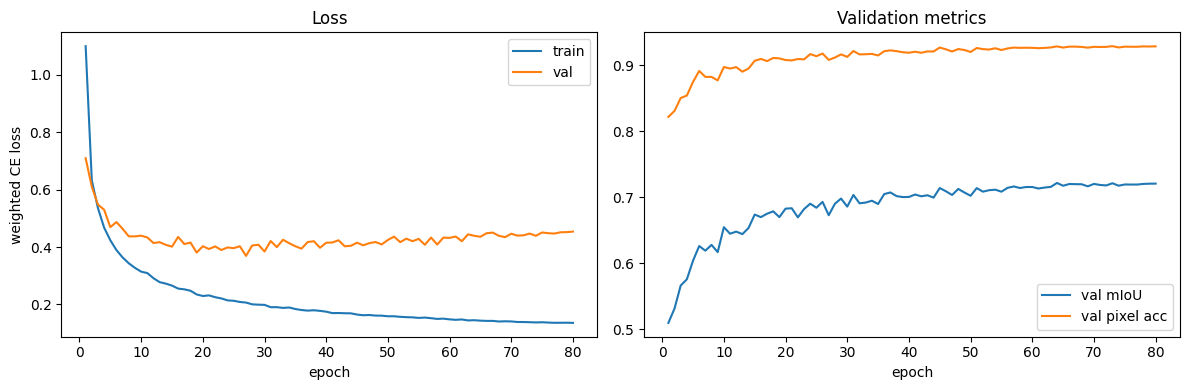

In [ ]:
pd.DataFrame(history).to_csv(f'{OUT_DIR}/history.csv', index=False)

config = dict(
    arch='DeepLabV3Plus', encoder='resnet18', encoder_pretrain='imagenet',
    smp_version=smp.__version__, torch_version=torch.__version__,
    class_names=CLASS_NAMES, cmap=CMAP, in_h=IN_H, in_w=IN_W,
    mean=MEAN.tolist(), std=STD.tolist(), ignore_index=IGNORE,
    class_weights=class_w.tolist(), epochs=EPOCHS, batch=BATCH,
    lr_encoder=LR_ENC, lr_decoder=LR_DEC, weight_decay=WD,
    split=dict(train=len(Xtr), val=len(Xva),
               test=len(glob.glob(f'{ROOT}/test/*.png'))),
    best_val_miou=float(best_miou))
with open(f'{OUT_DIR}/config.json', 'w') as f:
    json.dump(config, f, indent=2)

h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoch, h.train_loss, label='train'); ax[0].plot(h.epoch, h.val_loss, label='val')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('weighted CE loss'); ax[0].legend(); ax[0].set_title('Loss')
ax[1].plot(h.epoch, h.val_miou, label='val mIoU'); ax[1].plot(h.epoch, h.val_pixel_acc, label='val pixel acc')
ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].set_title('Validation metrics')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/training_curves.png', dpi=150); plt.show()

In [11]:
model.load_state_dict(torch.load(f'{OUT_DIR}/best_model.pth', map_location=DEVICE))
model.eval()

@torch.no_grad()
def predict(rgb):
    """Full-size RGB -> full-size class-index mask.
    Same steps as local inference: resize to 384x512, run the model,
    upsample the class scores back to the original size, take argmax."""
    H, W = rgb.shape[:2]
    x = to_tensor(cv2.resize(rgb, (IN_W, IN_H), interpolation=cv2.INTER_AREA))[None].to(DEVICE)
    logits = F.interpolate(model(x).float(), size=(H, W), mode='bilinear', align_corners=False)
    return logits.argmax(1)[0].cpu().numpy().astype(np.uint8)

test_files = sorted(glob.glob(f'{ROOT}/test/*.png'))
sample_idx = set(np.linspace(0, len(test_files) - 1, 6).astype(int).tolist())
cm_test = np.zeros((K, K), np.int64); samples = []
t0 = time.time()
for i, f in enumerate(test_files):
    rgb = read_rgb(f)
    gt  = rgb_to_mask(read_rgb(label_path('test', f)))
    pred = predict(rgb)
    v = gt != IGNORE
    cm_test += np.bincount(gt[v].astype(np.int64) * K + pred[v],
                           minlength=K * K).reshape(K, K)
    if i in sample_idx:
        samples.append((os.path.basename(f), rgb, gt, pred))
print(f'{len(test_files)} test images in {time.time() - t0:.0f}s')

st = scores(cm_test)
print(f'\nGlobal pixel accuracy : {st["pixel_acc"]:.4f}')
print(f'Mean class accuracy   : {st["mean_acc"]:.4f}')
print(f'Mean IoU (mIoU)       : {st["miou"]:.4f}\n')
per_class = pd.DataFrame({'class': CLASS_NAMES, 'IoU': st['iou'], 'accuracy': st['class_acc']})
print(per_class.to_string(index=False, float_format='%.4f'))

per_class.to_csv(f'{OUT_DIR}/test_per_class.csv', index=False)
with open(f'{OUT_DIR}/test_metrics.json', 'w') as f:
    json.dump(dict(pixel_acc=float(st['pixel_acc']), mean_acc=float(st['mean_acc']),
                   miou=float(st['miou']),
                   iou={c: float(v) for c, v in zip(CLASS_NAMES, st['iou'])},
                   class_acc={c: float(v) for c, v in zip(CLASS_NAMES, st['class_acc'])},
                   confusion=cm_test.tolist()), f, indent=2)

232 test images in 64s

Global pixel accuracy : 0.9120
Mean class accuracy   : 0.8370
Mean IoU (mIoU)       : 0.6787

     class    IoU  accuracy
       Sky 0.9189    0.9451
  Building 0.8396    0.8901
      Pole 0.2755    0.6910
      Road 0.9400    0.9503
  Pavement 0.7727    0.9092
      Tree 0.7890    0.8957
SignSymbol 0.4656    0.7071
     Fence 0.5514    0.7654
       Car 0.8172    0.8978
Pedestrian 0.5006    0.8372
 Bicyclist 0.5950    0.7176


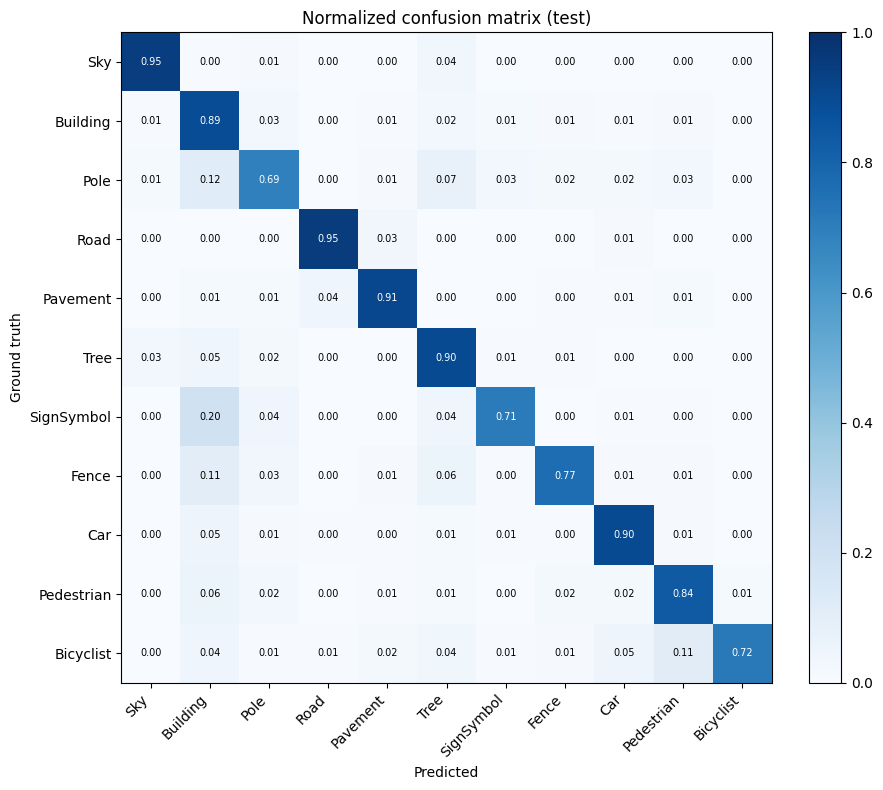

In [12]:
cmn = cm_test / np.maximum(cm_test.sum(1, keepdims=True), 1)   # each row sums to 1
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted'); ax.set_ylabel('Ground truth')
for r in range(K):
    for c in range(K):
        ax.text(c, r, f'{cmn[r, c]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if cmn[r, c] > 0.5 else 'black')
plt.colorbar(im, fraction=0.046); ax.set_title('Normalized confusion matrix (test)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=150); plt.show()

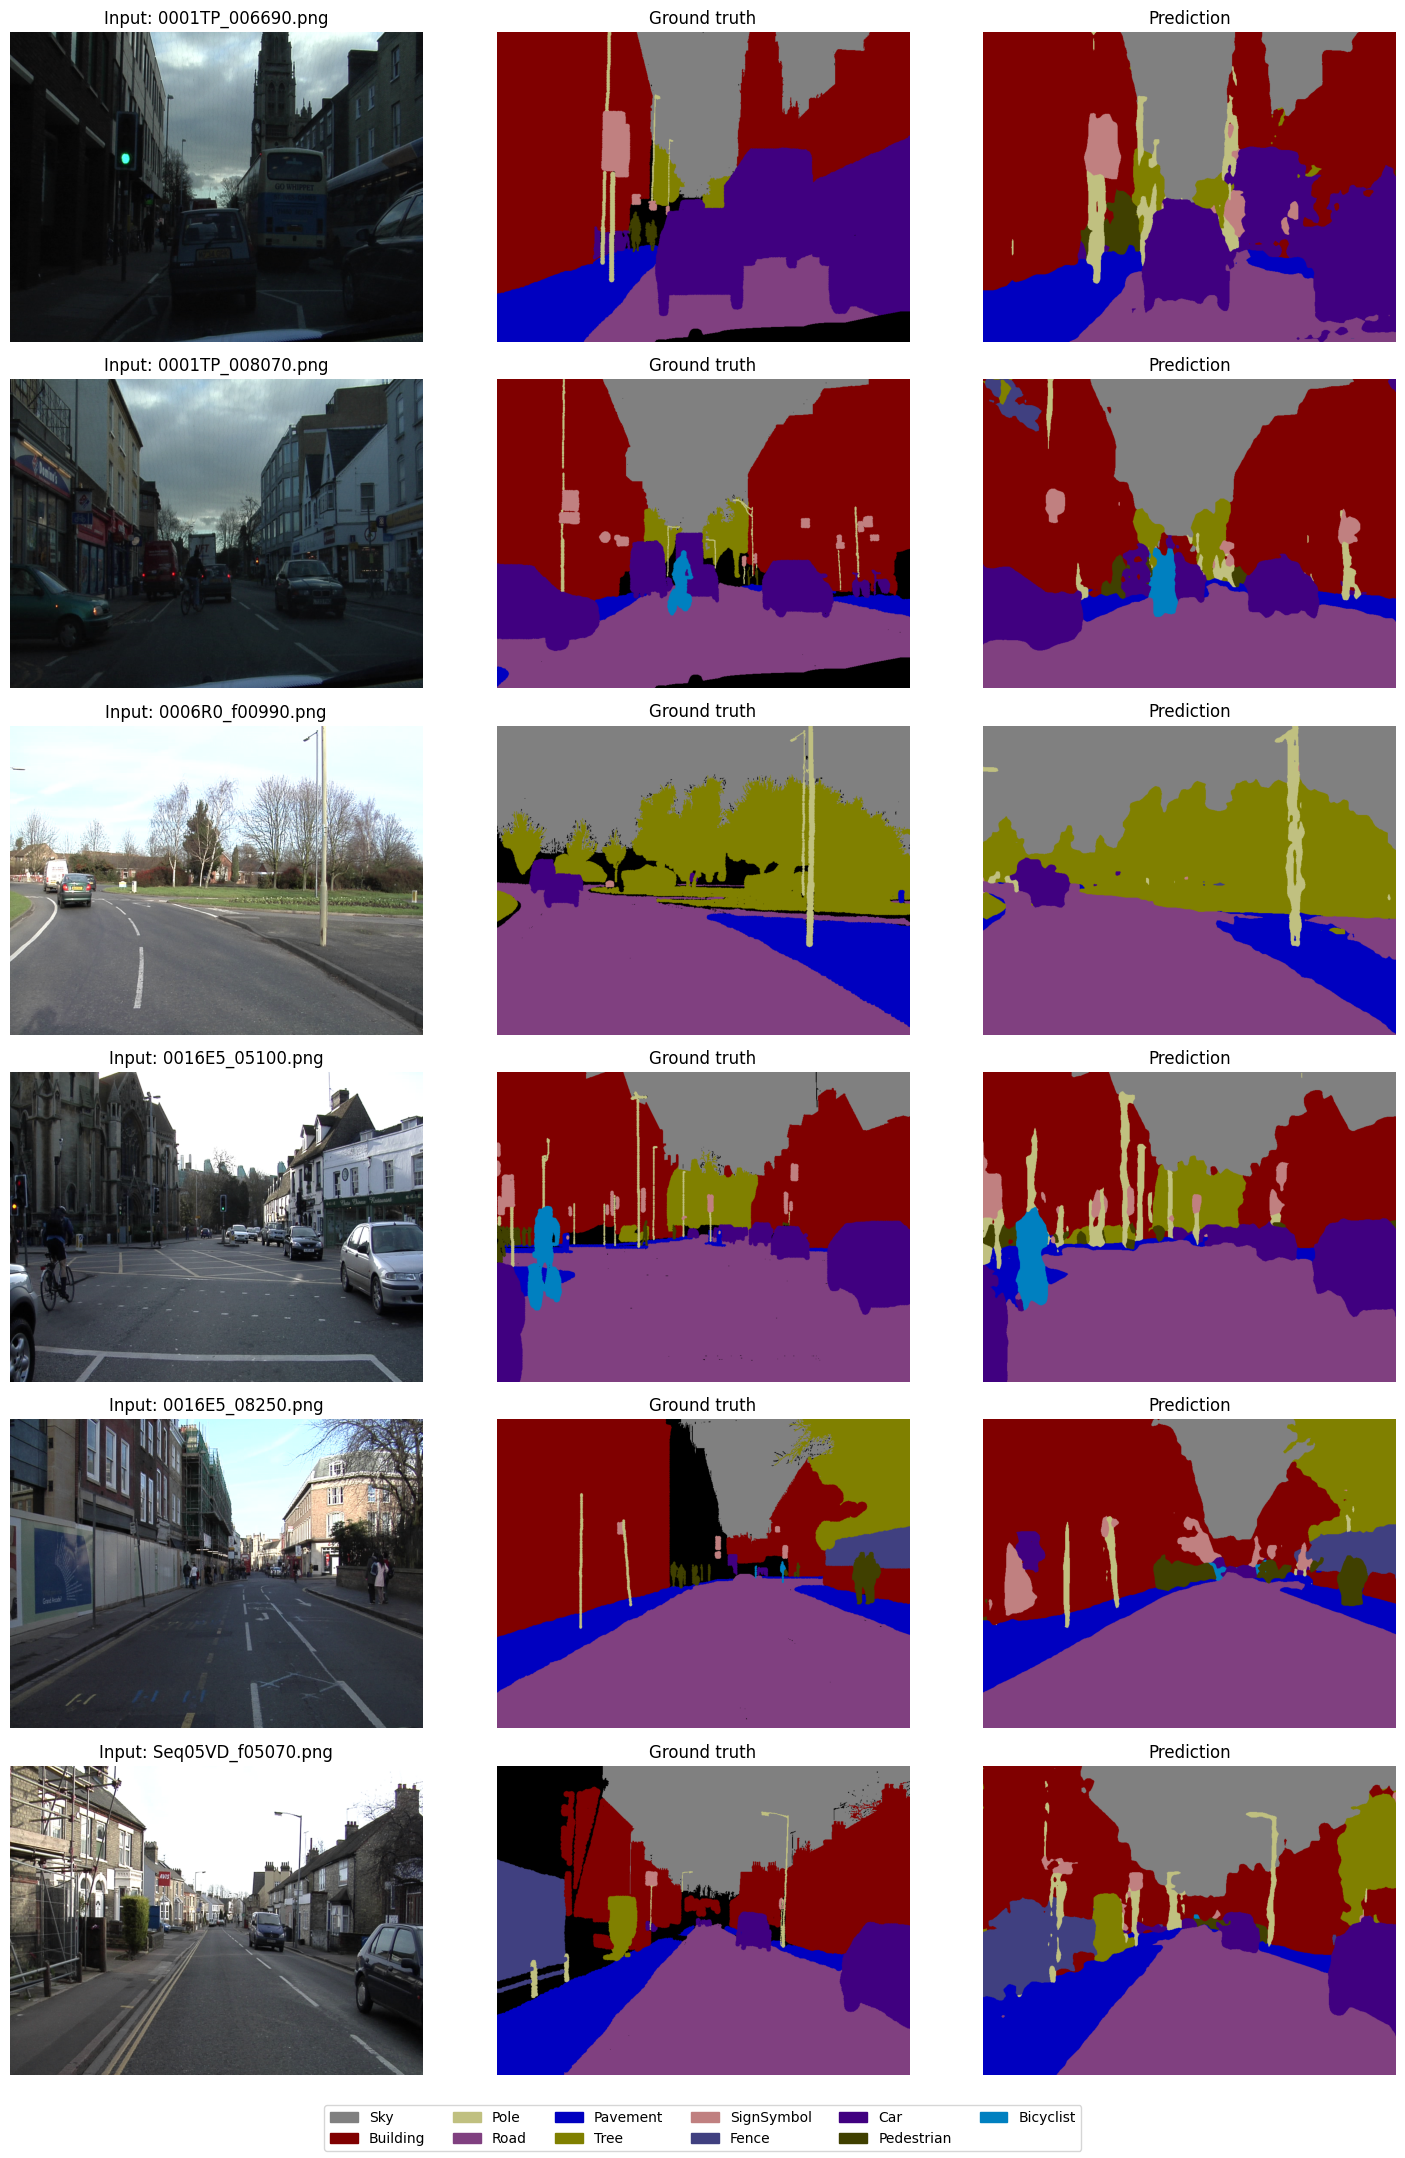

In [13]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(len(samples), 3, figsize=(15, 3.6 * len(samples)))
for r, (name, rgb, gt, pred) in enumerate(samples):
    for c, (im, title) in enumerate([(rgb, f'Input: {name}'),
                                     (colorize(gt), 'Ground truth'),
                                     (colorize(pred), 'Prediction')]):
        axes[r, c].imshow(im); axes[r, c].set_title(title); axes[r, c].axis('off')
handles = [Patch(color=np.array(CMAP[k]) / 255, label=CLASS_NAMES[k]) for k in range(K)]
fig.legend(handles=handles, loc='lower center', ncol=6, fontsize=10)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(f'{OUT_DIR}/qualitative_results.png', dpi=120); plt.show()

# Also save each sample separately (handy for the report)
os.makedirs(f'{OUT_DIR}/samples', exist_ok=True)
for name, rgb, gt, pred in samples:
    base = os.path.splitext(name)[0]
    cv2.imwrite(f'{OUT_DIR}/samples/{base}_input.png', cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
    cv2.imwrite(f'{OUT_DIR}/samples/{base}_gt.png',    cv2.cvtColor(colorize(gt), cv2.COLOR_RGB2BGR))
    cv2.imwrite(f'{OUT_DIR}/samples/{base}_pred.png',  cv2.cvtColor(colorize(pred), cv2.COLOR_RGB2BGR))

In [14]:
for f in sorted(glob.glob(f'{OUT_DIR}/**/*', recursive=True)):
    if os.path.isfile(f):
        print(f'{os.path.getsize(f) / 1e6:8.2f} MB  {f}')

    2.68 MB  /kaggle/working/__notebook__.ipynb
   49.45 MB  /kaggle/working/best_model.pth
    0.00 MB  /kaggle/working/config.json
    0.12 MB  /kaggle/working/confusion_matrix.png
    0.01 MB  /kaggle/working/history.csv
    2.22 MB  /kaggle/working/qualitative_results.png
    0.02 MB  /kaggle/working/samples/0001TP_006690_gt.png
    0.85 MB  /kaggle/working/samples/0001TP_006690_input.png
    0.02 MB  /kaggle/working/samples/0001TP_006690_pred.png
    0.02 MB  /kaggle/working/samples/0001TP_008070_gt.png
    0.97 MB  /kaggle/working/samples/0001TP_008070_input.png
    0.02 MB  /kaggle/working/samples/0001TP_008070_pred.png
    0.03 MB  /kaggle/working/samples/0006R0_f00990_gt.png
    1.01 MB  /kaggle/working/samples/0006R0_f00990_input.png
    0.01 MB  /kaggle/working/samples/0006R0_f00990_pred.png
    0.03 MB  /kaggle/working/samples/0016E5_05100_gt.png
    1.03 MB  /kaggle/working/samples/0016E5_05100_input.png
    0.02 MB  /kaggle/working/samples/0016E5_05100_pred.png
    0.02 M